# sklearn 风格时序预测：模型、参数、损失和季节性

独立读取同目录的 `energy_dataset.csv`，用截至小时 t 的信息预测 t+1 小时电价。
练习假设 t 的价格和负荷已发布；这是逐小时更新信息的一步预测。

**数据规则：** 先在完整小时索引上生成滞后和目标，再删除缺失样本；Pipeline 不处理缺失。
线性模型的 Pipeline 只有标准化和回归；树模型的 Pipeline 只有回归器。

**阅读路线：** 00—02 数据和接口；03—10 八种模型；04A 季节性对比；10A XGBoost 早停；
11—13 参数和指标；14—16 修改训练损失；17 按日期做时间交叉验证；18 自定义评分；19 最终测试。

| 模型 | 主要配置 | 拟合后常看的结果 |
|---|---|---|
| LinearRegression | `fit_intercept` | `coef_`, `intercept_` |
| Ridge | `alpha`, `solver` | `coef_`, `intercept_` |
| Lasso | `alpha`, `max_iter`, `tol` | `coef_`, `n_iter_`, `dual_gap_` |
| ElasticNet | `alpha`, `l1_ratio` | `coef_`, `n_iter_` |
| DecisionTreeRegressor | `max_depth`, `min_samples_leaf`, `criterion` | `feature_importances_` |
| RandomForestRegressor | `n_estimators`, `max_depth`, `max_features` | `estimators_`, `feature_importances_` |
| GradientBoostingRegressor | `loss`, `n_estimators`, `learning_rate` | `train_score_` |
| XGBRegressor | `objective`, `eval_metric`, `reg_alpha`, `reg_lambda` | `evals_result()`, `get_booster()` |

XGBoost 是独立库，提供兼容 sklearn 的接口；需要安装 `xgboost`。
本机验证版本为 sklearn 1.6.1、XGBoost 2.1.4（兼容当前 Python 3.9）。

## 00. 构造预测样本：保留完整时间轴，再删除缺失样本

使用 UTC，先验证数据每小时连续。生成全部 shift / rolling 后，统一删除任一必需字段缺失的行。
**不能先删除原始缺失行再 shift，否则上一行可能不再是上一小时。**
`rolling(24)` 包含当前 t，符合本题假设；整个预测过程不读取 t+1 的实际信息。

季节性分为两类输入：

| 类型 | 本例特征 | 作用 |
|---|---|---|
| 过去相似时刻的数值 | 目标前 24 小时、168 小时的价格 | 给模型已发生的日/周周期信息 |
| 目标时刻的日历位置 | 小时、星期、年度进度的 sin/cos，以及周末标记 | 描述可提前知道的周期位置 |

目标为 t+1，因此“目标前 24 小时”在当前行是 `shift(23)`；前 168 小时是 `shift(167)`。
它们是 UTC 下的固定小时滞后；当地作息/节假日分析应先确认地区时区和日历，夏令时边界还需单独考虑。
下方日历特征使用 UTC；确认当地时区后，可仅把 `calendar_time` 转成当地时间再提取。

<details>
<summary>本机 NumPy 兼容说明（可跳过）</summary>

本机旧版 NumPy 的 macOS 矩阵警告已经独立计算核对；下方只过滤该环境下对应位置的已知警告，
保留有限值检查及其他数值警告。背景见 [NumPy 问题记录](https://github.com/numpy/numpy/issues/28687)。

</details>

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import sklearn
import xgboost
import platform
import warnings

if platform.system() == "Darwin" and np.__version__ == "2.0.2":
    warnings.filterwarnings(
        "ignore",
        message=r"(divide by zero|overflow|invalid value) encountered in matmul",
        category=RuntimeWarning,
        module=r"sklearn\.(linear_model\._base|utils\.extmath)",
    )

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, SGDRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    mean_pinball_loss, make_scorer,
)
from sklearn.model_selection import GridSearchCV
from xgboost import XGBRegressor

data = pd.read_csv(Path("energy_dataset.csv"))
data["time"] = pd.to_datetime(data["time"], utc=True)
data = data.sort_values("time").set_index("time")
assert data.index.is_unique
gaps = data.index.to_series().diff().dropna()
assert len(gaps) > 0 and gaps.eq(pd.Timedelta(hours=1)).all()

# 在完整时间轴上创建特征，不能在这之前删除缺失行
samples = pd.DataFrame(index=data.index)
samples["price_now"] = data["price actual"]
samples["price_lag1"] = data["price actual"].shift(1)
samples["price_mean24"] = data["price actual"].rolling(24, min_periods=24).mean()
samples["load_now"] = data["total load actual"]
samples["price_same_hour_yesterday"] = data["price actual"].shift(23)
samples["price_same_hour_lastweek"] = data["price actual"].shift(167)
samples["target_time"] = samples.index + pd.Timedelta(hours=1)
samples["target"] = data["price actual"].shift(-1)

calendar_time = samples["target_time"]  # 当前使用 UTC
hour = calendar_time.dt.hour
weekday = calendar_time.dt.dayofweek
samples["hour_sin"] = np.sin(2 * np.pi * hour / 24)
samples["hour_cos"] = np.cos(2 * np.pi * hour / 24)
samples["week_sin"] = np.sin(2 * np.pi * weekday / 7)
samples["week_cos"] = np.cos(2 * np.pi * weekday / 7)
samples["is_weekend"] = (weekday >= 5).astype(int)

# 年度进度：区分闰年，不把所有年份固定成 365 天
days_in_year = np.where(calendar_time.dt.is_leap_year, 366, 365)
year_phase = (calendar_time.dt.dayofyear - 1 + hour / 24) / days_in_year
samples["year_sin"] = np.sin(2 * np.pi * year_phase)
samples["year_cos"] = np.cos(2 * np.pi * year_phase)

base_features = ["price_now", "price_lag1", "price_mean24", "load_now"]
seasonal_features = [
    "price_same_hour_yesterday", "price_same_hour_lastweek",
    "hour_sin", "hour_cos", "week_sin", "week_cos",
    "is_weekend", "year_sin", "year_cos",
]
features = base_features + seasonal_features

rows_before = len(samples)
missing_summary = samples[features + ["target"]].isna().sum()
samples = samples.dropna(subset=features + ["target"]).copy()
assert samples[features + ["target"]].notna().all().all()

print("sklearn:", sklearn.__version__, "XGBoost:", xgboost.__version__)
print("Rows before / after complete-case filtering:", rows_before, len(samples))
display(missing_summary.to_frame("missing_before_filtering"))
display(samples[["target_time"] + features + ["target"]].head())

sklearn: 1.6.1 XGBoost: 2.1.4
Rows before / after complete-case filtering: 35064 34866


,missing_before_filtering
price_now,0
price_lag1,1
price_mean24,23
load_now,36
price_same_hour_yesterday,23
price_same_hour_lastweek,167
hour_sin,0
hour_cos,0
week_sin,0
week_cos,0


,target_time,price_now,price_lag1,price_mean24,load_now,price_same_hour_yesterday,price_same_hour_lastweek,hour_sin,hour_cos,week_sin,week_cos,is_weekend,year_sin,year_cos,target
time,,,,,,,,,,,,,,,
2015-01-07 22:00:00+00:00,2015-01-07 23:00:00+00:00,75.07,78.15,78.775833,30477.0,67.24,65.41,-0.258819,0.965926,0.974928,-0.222521,0,0.119496,0.992835,73.73
2015-01-07 23:00:00+00:00,2015-01-08 00:00:00+00:00,73.73,75.07,79.046250,26788.0,64.17,64.92,0.000000,1.000000,0.433884,-0.900969,0,0.120208,0.992749,70.99
2015-01-08 00:00:00+00:00,2015-01-08 01:00:00+00:00,70.99,73.73,79.330417,25146.0,62.12,64.48,0.258819,0.965926,0.433884,-0.900969,0,0.120920,0.992662,68.30
2015-01-08 01:00:00+00:00,2015-01-08 02:00:00+00:00,68.30,70.99,79.587917,23889.0,62.11,59.32,0.500000,0.866025,0.433884,-0.900969,0,0.121632,0.992575,64.22
2015-01-08 02:00:00+00:00,2015-01-08 03:00:00+00:00,64.22,68.30,79.675833,23046.0,60.05,56.04,0.707107,0.707107,0.433884,-0.900969,0,0.122344,0.992488,63.53


## 01. 时间划分与统一评估


按目标时间划分：2015—2016 训练，2017 验证，2018 最终测试。
模型比较和调参都放在测试之前。
`X` 保持二维 DataFrame，`y` 是一维 Series；sklearn 按行位置配对，不自动根据时间索引对齐。
MAE、RMSE 越小越好；R² 越大越好，也可能为负。

In [2]:
target_time = samples["target_time"]
train = samples.loc[(target_time >= "2015-01-01") & (target_time < "2017-01-01")].copy()
val = samples.loc[(target_time >= "2017-01-01") & (target_time < "2018-01-01")].copy()
test = samples.loc[(target_time >= "2018-01-01") & (target_time < "2019-01-01")].copy()

X_train, y_train = train[features], train["target"]
X_val, y_val = val[features], val["target"]
X_test, y_test = test[features], test["target"]

def metrics(y_true, prediction):
    if not np.isfinite(np.asarray(prediction)).all():
        raise ValueError("模型产生了非有限预测，请先检查数值计算")
    return {
        "MAE": mean_absolute_error(y_true, prediction),
        "RMSE": np.sqrt(mean_squared_error(y_true, prediction)),
        "R2": r2_score(y_true, prediction),
    }

validation_records = []
fitted_models = {}

# 只是减少重复打印；模型的 fit 仍会在每个例子中显式写出来
def show_validation(name, fitted_model):
    result = metrics(y_val, fitted_model.predict(X_val))
    result["Train_MAE"] = mean_absolute_error(y_train, fitted_model.predict(X_train))
    result["model"] = name
    validation_records.append(result)
    fitted_models[name] = fitted_model
    display(pd.DataFrame([result]).set_index("model").round(4))

display(pd.DataFrame([
    {"split": name, "rows": len(part), "first_target": part["target_time"].min(),
     "last_target": part["target_time"].max()}
    for name, part in [("train", train), ("validation", val), ("test", test)]
]).set_index("split"))
validation_baselines = pd.DataFrame({
    "Current-price baseline": metrics(y_val, X_val["price_now"]),
    "Daily seasonal naive (24h)": metrics(y_val, X_val["price_same_hour_yesterday"]),
    "Weekly seasonal naive (168h)": metrics(y_val, X_val["price_same_hour_lastweek"]),
}).T
print("Validation baselines:")
display(validation_baselines.round(4))

,rows,first_target,last_target
split,,,
train,17351,2015-01-07 23:00:00+00:00,2016-12-31 23:00:00+00:00
validation,8758,2017-01-01 00:00:00+00:00,2017-12-31 23:00:00+00:00
test,8757,2018-01-01 00:00:00+00:00,2018-12-31 22:00:00+00:00


Validation baselines:


,MAE,RMSE,R2
Current-price baseline,2.3790,3.5140,0.9179
Daily seasonal naive (24h),5.1861,7.4918,0.6270
Weekly seasonal naive (168h),6.2694,8.8856,0.4753


## 02. Pipeline：线性模型标准化，树模型直接训练

缺失样本已在构造时间特征后移除，Pipeline 不包含缺失处理。
线性模型保留 StandardScaler；树模型使用单步骤 Pipeline，统一保持 `model__参数名` 的接口。
标准化参数仅从 fit 的训练数据学习。

In [3]:
def linear_pipeline(estimator):
    return Pipeline([
        ("scaler", StandardScaler()),
        ("model", estimator),
    ])

def tree_pipeline(estimator):
    return Pipeline([
        ("model", estimator),
    ])

example_pipeline = linear_pipeline(Ridge(alpha=10.0))
print(example_pipeline)

Pipeline(steps=[('scaler', StandardScaler()), ('model', Ridge(alpha=10.0))])


## 03. 普通线性回归 LinearRegression


`fit_intercept=True` 表示拟合截距。训练目标是最小二乘，没有通用的 `loss=` 参数。
本例使用标准化输入；系数的量纲会在第 12 节说明。

In [4]:
linear_model = linear_pipeline(LinearRegression(fit_intercept=True))
linear_model.fit(X_train, y_train)
linear_pred = linear_model.predict(X_val)
show_validation("Linear", linear_model)

,MAE,RMSE,R2,Train_MAE
model,,,,
Linear,1.8327,2.649,0.9534,2.1206


## 04. Ridge：L2 正则化线性回归


`alpha` 控制正则化强度，数值越大，惩罚越强。`solver="auto"` 自动选择求解方式。
改 `alpha` 调整的是正则化强度，数据拟合项仍是平方误差。
[Ridge 官方文档](https://scikit-learn.org/1.6/modules/generated/sklearn.linear_model.Ridge.html)

In [5]:
ridge_model = linear_pipeline(Ridge(alpha=10.0, solver="auto"))
ridge_model.fit(X_train, y_train)
show_validation("Ridge", ridge_model)

,MAE,RMSE,R2,Train_MAE
model,,,,
Ridge,1.8345,2.652,0.9533,2.1211


## 04A. 季节性：先比较基准，再做特征对照实验

时序季节性不要求先换模型：日/周/年度 sin/cos、周末或节假日标记、历史同一时刻值都可以作为输入。
sin/cos 只表达平滑的一阶周期，复杂日内形态可进一步尝试 one-hot、更多 Fourier 项或周期样条。
在已确认的地区日历上添加节假日信息，预测时需提前可知。

下面固定 Ridge 的配置，只比较“基础特征”和“增加季节性特征”。两者使用完全相同的样本。
本例年度规律只有约两年训练数据支撑，应在不同季节验证；不能凭一条平均曲线认定每年都稳定。
如果需要显式估计季节项，可以另学 SARIMA、ETS 等专门的时序模型；本笔记先练习回归特征法。
[周期编码的官方示例](https://scikit-learn.org/1.6/auto_examples/applications/plot_cyclical_feature_engineering.html)

In [6]:
base_ridge = linear_pipeline(Ridge(alpha=10.0))
base_ridge.fit(X_train[base_features], y_train)
seasonal_comparison = pd.DataFrame({
    "Base features": metrics(y_val, base_ridge.predict(X_val[base_features])),
    "Base + seasonal features": metrics(y_val, ridge_model.predict(X_val)),
}).T
display(seasonal_comparison.round(4))
display(validation_baselines.round(4))

,MAE,RMSE,R2
Base features,1.8918,2.7787,0.9487
Base + seasonal features,1.8345,2.6520,0.9533


,MAE,RMSE,R2
Current-price baseline,2.3790,3.5140,0.9179
Daily seasonal naive (24h),5.1861,7.4918,0.6270
Weekly seasonal naive (168h),6.2694,8.8856,0.4753


## 05. Lasso：L1 正则化，可以把部分系数压到零


`alpha` 控制惩罚；`max_iter` 是迭代上限；`tol` 是收敛容差。
系数变成零不等于该变量在业务上没有作用。
Ridge 和 Lasso 的目标函数归一化约定不同，不应把相同 alpha 理解成相同程度的正则化。

In [7]:
lasso_model = linear_pipeline(Lasso(alpha=0.01, max_iter=20000, tol=1e-4))
lasso_model.fit(X_train, y_train)
show_validation("Lasso", lasso_model)
print("Nonzero coefficients:", np.count_nonzero(lasso_model.named_steps["model"].coef_))

,MAE,RMSE,R2,Train_MAE
model,,,,
Lasso,1.8301,2.6529,0.9532,2.1191


Nonzero coefficients: 12


## 06. ElasticNet：组合 L1 和 L2


`alpha` 控制总体正则化强度，`l1_ratio` 控制其中 L1 的比例。
例如 0.5 表示两类惩罚混合；1 表示 L1。这里用混合配置演示。

In [8]:
elastic_model = linear_pipeline(
    ElasticNet(alpha=0.01, l1_ratio=0.5, max_iter=20000, tol=1e-4)
)
elastic_model.fit(X_train, y_train)
show_validation("ElasticNet", elastic_model)

,MAE,RMSE,R2,Train_MAE
model,,,,
ElasticNet,1.8775,2.7107,0.9512,2.1586


## 07. 单棵回归树 DecisionTreeRegressor


`max_depth` 限制树深；`min_samples_leaf` 限制叶子的最少样本数。
`criterion` 控制分裂评价准则，例如 `squared_error` 或 `absolute_error`。
它不是所有模型都通用的 `loss` 参数。只追求训练误差可能导致树过拟合。

In [9]:
tree_model = tree_pipeline(DecisionTreeRegressor(
    max_depth=6,
    min_samples_leaf=30,
    criterion="squared_error",
    random_state=42,
))
tree_model.fit(X_train, y_train)
show_validation("Decision tree", tree_model)

tree_step = tree_model.named_steps["model"]
print("Actual depth:", tree_step.get_depth())
print("Leaf count:", tree_step.get_n_leaves())

,MAE,RMSE,R2,Train_MAE
model,,,,
Decision tree,2.4591,3.5568,0.9159,2.318


Actual depth: 6
Leaf count: 64


## 08. 随机森林 RandomForestRegressor


多棵树平均预测。`n_estimators` 是树的数量，`max_features` 是每次分裂考虑的特征数/比例。
`n_jobs=2` 使用两个并行任务，避免示例占用全部 CPU。
时间划分仍由外部负责，树内部的抽样不替代面向未来的验证。

In [10]:
forest_model = tree_pipeline(RandomForestRegressor(
    n_estimators=80,
    max_depth=12,
    min_samples_leaf=10,
    max_features=0.8,
    n_jobs=2,
    random_state=42,
))
forest_model.fit(X_train, y_train)
show_validation("Random forest", forest_model)
print("Number of fitted trees:", len(forest_model.named_steps["model"].estimators_))

,MAE,RMSE,R2,Train_MAE
model,,,,
Random forest,1.8747,2.8491,0.9461,1.4435


Number of fitted trees: 80


## 09. 梯度提升树 GradientBoostingRegressor


`learning_rate` 控制每棵树的贡献，`n_estimators` 控制提升轮数，`max_depth` 控制单棵树复杂度。
该模型可通过 `loss` 切换平方误差、绝对误差、Huber 或分位数目标。
这里关闭内部早停，统一使用前面按时间切好的验证集。
[官方文档](https://scikit-learn.org/1.6/modules/generated/sklearn.ensemble.GradientBoostingRegressor.html)

In [11]:
gboost_model = tree_pipeline(GradientBoostingRegressor(
    loss="squared_error",
    n_estimators=80,
    learning_rate=0.08,
    max_depth=3,
    min_samples_leaf=20,
    n_iter_no_change=None,
    random_state=42,
))
gboost_model.fit(X_train, y_train)
show_validation("Gradient boosting", gboost_model)
print("First five training-loss values:")
print(gboost_model.named_steps["model"].train_score_[:5])

,MAE,RMSE,R2,Train_MAE
model,,,,
Gradient boosting,1.9806,2.966,0.9415,1.8767


First five training-loss values:
[192.46490068 165.97551032 143.41494577 124.24076977 107.95789977]


## 10. XGBoost：XGBRegressor 的 sklearn 兼容接口

XGBoost 是独立库，调用方式同样是 fit / predict / get_params / set_params。
`objective` 是训练目标；`eval_metric` 是训练时记录的评价指标，两者可以不同。
`reg_alpha` / `reg_lambda` 控制 L1 / L2 惩罚；不要与 sklearn Ridge 的目标归一化直接等同。
这里固定 200 轮，使用已经按时间切好的验证集记录 MAE。
树 Pipeline 没有预处理，因此 `model__eval_set` 中的 X_val 可直接使用。
[XGBoost 官方接口说明](https://xgboost.readthedocs.io/en/stable/python/sklearn_estimator.html)

In [12]:
xgb_model = tree_pipeline(XGBRegressor(
    objective="reg:squarederror",
    eval_metric="mae",
    n_estimators=200,
    learning_rate=0.05,
    max_depth=4,
    min_child_weight=5,
    subsample=0.9,
    colsample_bytree=0.9,
    reg_alpha=0.0,
    reg_lambda=1.0,
    n_jobs=2,
    random_state=42,
))
xgb_model.fit(
    X_train, y_train,
    model__eval_set=[(X_val, y_val)],
    model__verbose=False,
)
show_validation("XGBoost", xgb_model)

xgb_step = xgb_model.named_steps["model"]
print("Selected native parameters:")
display(pd.Series({key: xgb_step.get_params()[key] for key in [
    "objective", "eval_metric", "max_depth", "reg_alpha", "reg_lambda",
]}).to_frame("value"))
print("Validation MAE, last 5 rounds:", xgb_step.evals_result()["validation_0"]["mae"][-5:])
print("Booster rounds:", xgb_step.get_booster().num_boosted_rounds())

,MAE,RMSE,R2,Train_MAE
model,,,,
XGBoost,1.923,2.8929,0.9444,1.6889


Selected native parameters:


,value
objective,reg:squarederror
eval_metric,mae
max_depth,4
reg_alpha,0.0
reg_lambda,1.0


Validation MAE, last 5 rounds: [1.9246624504275778, 1.9248438035007154, 1.924350049675913, 1.9231659681673436, 1.922966302543722]
Booster rounds: 200


## 10A. XGBoost 早停、最佳轮数和训练记录

`early_stopping_rounds` 放在构造函数中；`eval_set` 由 fit 接收。
用 2017 验证集早停，最终测试集不传给 eval_set。
`best_iteration` 从 0 开始，实际轮数是它加 1；`evals_result()` 返回每轮的监控记录。
如果选用这个早停方案最终重训：固定最佳轮数、关闭早停，再用训练＋验证数据 fit。
此处作为接口示例，主模型排名仍使用第 10 节固定轮数的 XGBoost。

早停不一定触发：若仍在改善，训练会达到设置的轮数上限。本次示例达到 600 轮；这不代表 early_stopping_rounds 参数失效。

In [13]:
xgb_early = clone(xgb_model.named_steps["model"]).set_params(
    n_estimators=600, early_stopping_rounds=30,
)
xgb_early.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
print("Best iteration (zero-based):", xgb_early.best_iteration)
print("Best validation MAE:", xgb_early.best_score)
xgb_history = pd.DataFrame(xgb_early.evals_result()["validation_0"])
display(xgb_history.tail())

# 最终重训配置示例，不再用测试集早停
xgb_refit_configuration = clone(xgb_early).set_params(
    n_estimators=xgb_early.best_iteration + 1,
    early_stopping_rounds=None,
)
print("Refit rounds:", xgb_refit_configuration.n_estimators)

Best iteration (zero-based): 599
Best validation MAE: 1.836648064787787


,mae
595,1.837968
596,1.838081
597,1.837798
598,1.837764
599,1.836648


Refit rounds: 600


## 11. 获取配置 get_params，修改配置 set_params


`get_params()` 返回的是配置，例如 alpha、树深；它不返回学习到的系数。
Pipeline 的 `deep=True` 会列出内部参数，`model__alpha` 中双下划线表示“model 步骤里的 alpha”。
**set_params 不会自动重新训练。** 改完配置需要再次 fit。
`clone()` 复制配置，产生未拟合的新模型，方便保留原模型用于比较。

GradientBoosting 还能通过 `train_score_` 读取每轮训练目标值；它不是所有模型都有的通用属性。

In [14]:
# 单独看 Ridge 这一层的配置
print("Estimator parameters:")
print(ridge_model.named_steps["model"].get_params())

# Pipeline 包含所有步骤的配置，下面只筛选 model 的参数
model_parameters = {
    key: value for key, value in ridge_model.get_params(deep=True).items()
    if key.startswith("model__")
}
print("Pipeline model parameters:")
print(model_parameters)

ridge_changed = clone(ridge_model)
ridge_changed.set_params(model__alpha=100.0)
ridge_changed.fit(X_train, y_train)
print("New alpha:", ridge_changed.get_params()["model__alpha"])
display(pd.DataFrame([metrics(y_val, ridge_changed.predict(X_val))]).round(4))

print("GradientBoosting training loss, last 5 rounds:")
print(gboost_model.named_steps["model"].train_score_[-5:])

Estimator parameters:
{'alpha': 10.0, 'copy_X': True, 'fit_intercept': True, 'max_iter': None, 'positive': False, 'random_state': None, 'solver': 'auto', 'tol': 0.0001}
Pipeline model parameters:
{'model__alpha': 10.0, 'model__copy_X': True, 'model__fit_intercept': True, 'model__max_iter': None, 'model__positive': False, 'model__random_state': None, 'model__solver': 'auto', 'model__tol': 0.0001}
New alpha: 100.0


,MAE,RMSE,R2
0,1.8846,2.7169,0.9509


GradientBoosting training loss, last 5 rounds:
[6.91276894 6.90048807 6.87195032 6.85621157 6.83696695]


## 12. 获取拟合后的系数、截距、迭代信息和树的重要性


拟合结果通常是末尾带下划线的属性，例如 `coef_`、`intercept_`，需要先 fit。
标准化后的线性系数对应“标准化输入增加 1”的变化，并非原始单位增加 1。
下面同时换算回输入的原始单位。
系数和树的不纯度重要性都不能直接解释为因果效应；相关特征可能分摊或替代彼此的贡献。

In [15]:
ridge_step = ridge_model.named_steps["model"]
scaler = ridge_model.named_steps["scaler"]
coefficient_table = pd.DataFrame({
    "standardized_coef": ridge_step.coef_,
    "original_unit_coef": ridge_step.coef_ / scaler.scale_,
}, index=features)
display(coefficient_table.round(5))
print("Intercept for standardized inputs:", ridge_step.intercept_)
original_intercept = ridge_step.intercept_ - np.dot(
    ridge_step.coef_, scaler.mean_ / scaler.scale_
)
print("Intercept for original-unit inputs:", original_intercept)

print("Lasso iterations:", lasso_model.named_steps["model"].n_iter_)
print("Lasso dual gap:", lasso_model.named_steps["model"].dual_gap_)
print("Feature count:", ridge_model.n_features_in_)

importance = pd.Series(
    forest_model.named_steps["model"].feature_importances_,
    index=features, name="impurity_importance",
).sort_values(ascending=False)
display(importance.to_frame().round(4))

,standardized_coef,original_unit_coef
price_now,18.78969,1.25652
price_lag1,-7.04042,-0.47087
price_mean24,1.31566,0.10382
load_now,-0.44284,-0.00010
price_same_hour_yesterday,0.77657,0.05183
price_same_hour_lastweek,0.90835,0.06054
hour_sin,-0.09264,-0.13103
hour_cos,-0.69333,-0.98038
week_sin,-0.25198,-0.35644
week_cos,0.30741,0.43464


Intercept for standardized inputs: 54.26550170019021
Intercept for original-unit inputs: 3.1155285711687313
Lasso iterations: 128
Lasso dual gap: 0.021287946781140203
Feature count: 13


,impurity_importance
price_now,0.7467
price_lag1,0.1700
price_mean24,0.0294
hour_cos,0.0186
price_same_hour_lastweek,0.0171
price_same_hour_yesterday,0.0063
hour_sin,0.0063
year_cos,0.0019
load_now,0.0013
year_sin,0.0012


## 13. 训练损失、评价指标和搜索评分是三件事

| 位置 | 决定什么 | 例子 |
|---|---|---|
| 模型训练目标 | fit 过程中优化什么 | `GradientBoostingRegressor(loss="absolute_error")` |
| 外部评价指标 | predict 后如何报告误差 | `mean_absolute_error(y, pred)` |
| 搜索评分 scoring | 多组配置中选谁 | `GridSearchCV(scoring="neg_mean_absolute_error")` |

把外部评价改成 MAE，不会自动把 Ridge 的训练目标变成绝对误差。
sklearn 这些回归器的 `.score(X, y)` 通常返回 R²，不是训练损失，也不是 MAE。

| 模型 | 能否通过一个参数换训练损失 |
|---|---|
| LinearRegression | 没有 `loss=`，固定最小二乘 |
| Ridge / Lasso / ElasticNet | 拟合项仍是平方误差，alpha 调的是正则化 |
| DecisionTree / RandomForest | 使用 `criterion=` 设置分裂准则 |
| GradientBoosting | `loss="squared_error" / "absolute_error" / "huber" / "quantile"` |
| XGBoost | 用 `objective="reg:squarederror" / "reg:absoluteerror"` 等；`eval_metric` 只改监控指标 |
| SGDRegressor | 可用 `loss="squared_error"` 或 `"huber"` 等 |

训练损失可选项由每个 estimator 的接口决定，不能给任意模型直接传入任意自定义函数。
[评价与 scoring 官方说明](https://scikit-learn.org/1.6/modules/model_evaluation.html)

In [16]:
prediction = ridge_model.predict(X_val)
print("MAE:", mean_absolute_error(y_val, prediction))
print("RMSE:", np.sqrt(mean_squared_error(y_val, prediction)))
print("R2 from score():", ridge_model.score(X_val, y_val))

MAE: 1.8345495513669972
RMSE: 2.651993550951365
R2 from score(): 0.9532601023793955


## 14. 真正修改训练损失：GradientBoosting 的三个版本


以下保持其他参数一致，只切换 loss，并重新 fit。
平方误差对大残差惩罚更重；绝对误差对应条件中位数目标；Huber 在两类惩罚之间过渡。
`alpha` 在这个模型的 Huber 配置里控制阈值分位数，与 Ridge 的 alpha 含义不同。
这里单独比较损失示例，不把它们加入前面的主模型候选表。

In [17]:
loss_models = {}
loss_rows = []
for loss_name in ["squared_error", "absolute_error", "huber"]:
    loss_model = tree_pipeline(GradientBoostingRegressor(
        loss=loss_name, alpha=0.9,
        n_estimators=50, learning_rate=0.1,
        max_depth=2, min_samples_leaf=20,
        n_iter_no_change=None, random_state=42,
    ))
    loss_model.fit(X_train, y_train)
    loss_models[loss_name] = loss_model
    loss_rows.append({"training_loss": loss_name,
                      **metrics(y_val, loss_model.predict(X_val))})

display(pd.DataFrame(loss_rows).set_index("training_loss").round(4))

,MAE,RMSE,R2
training_loss,,,
squared_error,2.2114,3.5627,0.9156
absolute_error,2.4318,4.1740,0.8842
huber,2.2383,3.7158,0.9082


## 14A. XGBoost：objective 和 eval_metric 分开设置

`reg:squarederror` 优化平方误差；`reg:absoluteerror` 优化绝对误差。
两者都用 `eval_metric="mae"` 监控，体现训练目标与监控指标的区别。
`objective` 的可选名称依版本而定；下面已在 XGBoost 2.1.4 验证。
[目标函数官方参数说明](https://xgboost.readthedocs.io/en/stable/parameter.html)

In [18]:
xgb_objective_rows = []
for objective in ["reg:squarederror", "reg:absoluteerror"]:
    alternative = clone(xgb_model.named_steps["model"]).set_params(
        objective=objective, eval_metric="mae", n_estimators=120,
    )
    alternative.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
    xgb_objective_rows.append({
        "objective": objective,
        **metrics(y_val, alternative.predict(X_val)),
    })
display(pd.DataFrame(xgb_objective_rows).set_index("objective").round(4))

,MAE,RMSE,R2
objective,,,
reg:squarederror,1.9691,2.9826,0.9409
reg:absoluteerror,2.0770,3.2353,0.9304


## 15. 线性模型想换 loss：SGDRegressor


SGDRegressor 用迭代优化学习线性关系，支持可选的 loss。
它与 LinearRegression 的求解过程不同，学习率和收敛条件会影响结果。
`epsilon` 是 Huber 由平方惩罚转为线性惩罚的阈值；`alpha` 是正则化强度。
这里标准化 X，并用相同配置比较两种训练目标。
`shuffle=False` 保留每轮优化的样本顺序；真正防止时序泄漏仍靠特征、时间划分和训练内预处理。
[SGDRegressor 官方文档](https://scikit-learn.org/1.6/modules/generated/sklearn.linear_model.SGDRegressor.html)

In [19]:
sgd_rows = []
for loss_name in ["squared_error", "huber"]:
    sgd_model = linear_pipeline(SGDRegressor(
        loss=loss_name, epsilon=2.0,
        penalty="l2", alpha=0.0001,
        learning_rate="invscaling", eta0=0.005,
        max_iter=5000, tol=1e-4,
        early_stopping=False, shuffle=False,
        random_state=42,
    ))
    sgd_model.fit(X_train, y_train)
    sgd_rows.append({"training_loss": loss_name,
                     "iterations": sgd_model.named_steps["model"].n_iter_,
                     **metrics(y_val, sgd_model.predict(X_val))})
display(pd.DataFrame(sgd_rows).set_index("training_loss").round(4))

,iterations,MAE,RMSE,R2
training_loss,,,,
squared_error,57,1.8315,2.6491,0.9534
huber,120,1.8168,2.6612,0.9529


## 16. 分位数损失：预测条件 90% 分位数

使用普通 GradientBoosting 的 `loss="quantile"`，通过 `alpha=0.9` 指定分位数。
使用对应的 pinball loss 评价；样本中实际值低于预测分位数的比例可辅助检查校准，
但不保证未来覆盖率正好为 90%。本例不参加点预测模型的 MAE 排名。

In [20]:
quantile_level = 0.9
quantile_model = tree_pipeline(GradientBoostingRegressor(
    loss="quantile", alpha=quantile_level,
    n_estimators=80, learning_rate=0.08,
    max_depth=2, min_samples_leaf=30,
    n_iter_no_change=None, random_state=42,
))
quantile_model.fit(X_train, y_train)
quantile_prediction = quantile_model.predict(X_val)
print("Pinball loss:", mean_pinball_loss(y_val, quantile_prediction, alpha=quantile_level))
print("Observed fraction at or below predicted q90:", np.mean(y_val.to_numpy() <= quantile_prediction))

Pinball loss: 0.6542623344298422
Observed fraction at or below predicted q90: 0.8972368120575474


## 17. 按日期构造时间交叉验证，再 GridSearchCV

删除缺失样本后，行数不再严格对应等长时间。这里按日历划分三个验证窗口，
各覆盖 2016 年连续四个月，让搜索看到不同季节；训练集始终只包含窗口之前的数据。
训练目标截止时间还留出一小时边界，避免紧贴未来信息。
GridSearchCV 可以直接接收由 `(训练位置, 验证位置)` 组成的列表。

搜索仍只使用 2015—2016；2017 为外部验证，2018 为最终测试。
Pipeline 确保每折标准化只学习该折训练部分。
`scoring="neg_mean_absolute_error"` 遵循分数越大越好，报告时取负号得到 MAE。

In [21]:
calendar_windows = [
    ("2016-01-01", "2016-05-01"),
    ("2016-05-01", "2016-09-01"),
    ("2016-09-01", "2017-01-01"),
]
time_cv = []
fold_rows = []
train_targets = train["target_time"]
for fold, (start, end) in enumerate(calendar_windows, start=1):
    start = pd.Timestamp(start, tz="UTC")
    end = pd.Timestamp(end, tz="UTC")
    train_positions = np.flatnonzero(train_targets < start - pd.Timedelta(hours=1))
    val_positions = np.flatnonzero((train_targets >= start) & (train_targets < end))
    time_cv.append((train_positions, val_positions))
    fold_rows.append({
        "fold": fold,
        "train_end_target": train_targets.iloc[train_positions[-1]],
        "validation_start_target": train_targets.iloc[val_positions[0]],
        "validation_end_target": train_targets.iloc[val_positions[-1]],
        "validation_rows": len(val_positions),
    })
display(pd.DataFrame(fold_rows).set_index("fold"))

ridge_search = GridSearchCV(
    estimator=linear_pipeline(Ridge()),
    param_grid={"model__alpha": [0.01, 0.1, 1.0, 10.0, 100.0]},
    scoring="neg_mean_absolute_error",
    cv=time_cv,
    n_jobs=1,
    refit=True,
    error_score="raise",
)
ridge_search.fit(X_train, y_train)
print("Best parameters:", ridge_search.best_params_)
print("Best CV MAE:", -ridge_search.best_score_)

search_table = pd.DataFrame(ridge_search.cv_results_)
search_table["CV_MAE"] = -search_table["mean_test_score"]
display(search_table[["param_model__alpha", "CV_MAE", "std_test_score"]].sort_values("CV_MAE"))
show_validation("Ridge tuned (calendar CV)", ridge_search.best_estimator_)

,train_end_target,validation_start_target,validation_end_target,validation_rows
fold,,,,
1,2015-12-31 22:00:00+00:00,2016-01-01 00:00:00+00:00,2016-04-30 23:00:00+00:00,2902
2,2016-04-30 22:00:00+00:00,2016-05-01 00:00:00+00:00,2016-08-31 23:00:00+00:00,2950
3,2016-08-31 22:00:00+00:00,2016-09-01 00:00:00+00:00,2016-12-31 23:00:00+00:00,2927


Best parameters: {'model__alpha': 1.0}
Best CV MAE: 1.8855331773442252


,param_model__alpha,CV_MAE,std_test_score
2,1.00,1.885533,0.292387
1,0.10,1.885555,0.291866
0,0.01,1.885558,0.291814
3,10.00,1.886131,0.297435
4,100.00,1.937877,0.336444


,MAE,RMSE,R2,Train_MAE
model,,,,
Ridge tuned (calendar CV),1.8328,2.6493,0.9534,2.1206


## 18. 自定义评分：低估价格时多罚一些


下面自定义一个非对称绝对误差：低估的残差权重为 2，高估为 1。
`make_scorer(..., greater_is_better=False)` 把它转换为搜索可用的负分。
可以将这个 scorer 传给 `GridSearchCV(scoring=...)`，改变选择配置的标准；
Ridge 每次 fit 的训练目标仍不变。

In [22]:
def asymmetric_mae(y_true, y_pred):
    residual = np.asarray(y_true) - np.asarray(y_pred)
    weights = np.where(residual > 0, 2.0, 1.0)
    return np.mean(weights * np.abs(residual))

asymmetric_scorer = make_scorer(asymmetric_mae, greater_is_better=False)
print("Custom error:", asymmetric_mae(y_val, ridge_model.predict(X_val)))
print("Scorer returns the negative:", asymmetric_scorer(ridge_model, X_val, y_val))

# 只展示配置。需要用自定义标准重新搜索时，再调用 .fit(X_train, y_train)
custom_search_configuration = GridSearchCV(
    linear_pipeline(Ridge()),
    param_grid={"model__alpha": [0.1, 1.0, 10.0]},
    scoring=asymmetric_scorer,
    cv=time_cv,
    n_jobs=1,
)

Custom error: 2.7529151655364865
Scorer returns the negative: -2.7529151655364865


## 19. 根据验证 MAE 选模型，重训后只做最终测试


主候选为八种模型及调参后的 Ridge，统一按 2017 验证 MAE 选择。
损失函数和分位数的独立教学例子不加入这里的候选。
比较多种方案会让验证表现乐观，因此保留 2018 作为最后的报告依据。
用 clone 取出选定配置，在训练＋验证数据上重新学习标准化和模型参数。

,MAE,RMSE,R2,Train_MAE
model,,,,
Lasso,1.8301,2.6529,0.9532,2.1191
Linear,1.8327,2.6490,0.9534,2.1206
Ridge tuned (calendar CV),1.8328,2.6493,0.9534,2.1206
Ridge,1.8345,2.6520,0.9533,2.1211
Random forest,1.8747,2.8491,0.9461,1.4435
ElasticNet,1.8775,2.7107,0.9512,2.1586
XGBoost,1.9230,2.8929,0.9444,1.6889
Gradient boosting,1.9806,2.9660,0.9415,1.8767
Decision tree,2.4591,3.5568,0.9159,2.3180


Selected by validation MAE: Lasso


,MAE,RMSE,R2
Current-price baseline,2.2591,3.3425,0.9251
Daily seasonal naive (24h),5.2050,7.6936,0.6030
Weekly seasonal naive (168h),6.3822,9.6303,0.3779
Lasso,1.8040,2.5999,0.9547


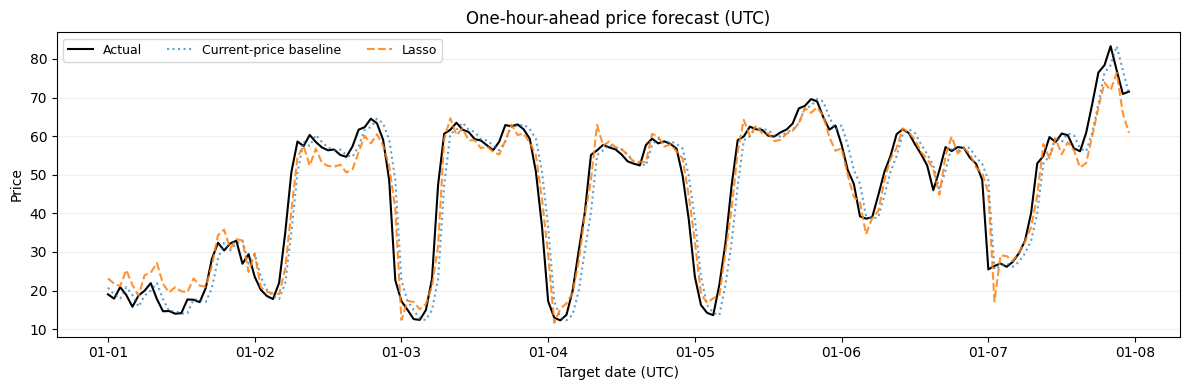

In [23]:
validation_results = pd.DataFrame(validation_records).set_index("model").sort_values("MAE")
display(validation_results.round(4))
best_name = validation_results.index[0]
print("Selected by validation MAE:", best_name)

train_val = pd.concat([train, val]).sort_index()
final_model = clone(fitted_models[best_name])
final_model.fit(train_val[features], train_val["target"])
final_prediction = final_model.predict(X_test)
baseline_prediction = X_test["price_now"].to_numpy()

test_results = pd.DataFrame({
    "Current-price baseline": metrics(y_test, baseline_prediction),
    "Daily seasonal naive (24h)": metrics(y_test, X_test["price_same_hour_yesterday"]),
    "Weekly seasonal naive (168h)": metrics(y_test, X_test["price_same_hour_lastweek"]),
    best_name: metrics(y_test, final_prediction),
}).T
display(test_results.round(4))

predictions = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Baseline": baseline_prediction,
    "Selected model": final_prediction,
}, index=pd.DatetimeIndex(test["target_time"], name="target_time"))
prediction_week = predictions.loc["2018-01-01":"2018-01-07"]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(prediction_week.index, prediction_week["Actual"], color="black", label="Actual")
ax.plot(prediction_week.index, prediction_week["Baseline"],
        linestyle=":", alpha=0.7, label="Current-price baseline")
ax.plot(prediction_week.index, prediction_week["Selected model"],
        linestyle="--", alpha=0.85, label=best_name)
ax.xaxis.set_major_locator(mdates.DayLocator(interval=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
ax.set(title="One-hour-ahead price forecast (UTC)", xlabel="Target date (UTC)", ylabel="Price")
ax.legend(ncol=3, fontsize=9)
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()

## 20. 季节性还没解释好吗？按目标月份检查误差

把绝对误差按目标月份汇总，观察是否集中在某些季节。
这里只报告最终测试的误差形态；新改动应回到训练/验证阶段选择，并留新的未来数据验证。
也可以继续按小时、工作日/周末分组，以及检查残差在 24、168 小时附近是否仍有关联。

In [24]:
absolute_error = (predictions["Actual"] - predictions["Selected model"]).abs()
monthly_error = absolute_error.groupby(absolute_error.index.month).agg(["mean", "count"])
monthly_error = monthly_error.rename(columns={"mean": "MAE", "count": "samples"})
monthly_error.index.name = "target_month_UTC"
display(monthly_error.round(4))

,MAE,samples
target_month_UTC,,
1,2.4054,744
2,1.9240,672
3,2.9348,744
4,2.3084,720
5,1.4570,744
6,1.2293,719
7,1.1291,743
8,1.3817,744
9,1.4319,720


## 最后留一份接口速查

```python
model.fit(X_train, y_train)
prediction = model.predict(X_val)
model.get_params()
model.set_params(model__alpha=1)   # Pipeline 内改 Ridge 配置；之后重新 fit
model.named_steps["model"].coef_  # 线性模型系数
model.score(X_val, y_val)          # 这些回归器通常返回 R²
```

- 缺失处理发生在生成全部时序特征之后；Pipeline 不进行填补。
- `coef_` 等是学习结果，`get_params()` 返回配置。
- sklearn 提升树用 `loss`；XGBoost 用 `objective`，`eval_metric` 是监控指标。
- 季节性先通过历史相似时刻、日历编码和验证对比研究；填入日历列不保证预测一定提升。
- 时间切分仍然需要自己设计；测试目标不参与训练、早停或调参。